# Health Insurance Premium Estimation
**TERV AIML · Track A - Regression · TFTPL310 (Trainer: Nithya)**

Predict the final annual premium (₹, before GST) an underwriter would set from the proposal form,
tested on the most recent six months (Jul - Dec 2025) and explained factor by factor with SHAP.

| Milestone | Day | Sections below |
|---|---|---|
| 1 Data understanding & quality | 1 | 1 |
| 2 Cleaning & EDA | 2-3 | 2, 3 |
| 3 Feature engineering & modelling | 4-5 | 4, 5 |
| 4 Evaluation & explanation | 6 | 6, 7 |
| 5 Insights & GitHub | 7 | 8 |

In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import shap
import joblib
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

from src import plots
from src.config import RAW_CSV, CLEAN_CSV, REPORT_DIR, MODEL_DIR, SPLIT_DATE, TARGET, ensure_dirs
from src.data_generation import write_raw_csv
from src.cleaning import data_quality_report, clean_proposals
from src.features import FeatureEngineer, build_models, transformed_frame
from src.modeling import time_split, compare_models, regression_metrics, error_by_age_band

ensure_dirs()


def show(fig, name):
    plots.save_fig(fig, name)      # every chart is also saved to outputs/figures/
    display(fig)
    plt.close(fig)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data understanding & quality (Milestone 1)
If `data/raw/health_insurance_proposals.csv` is missing, a synthetic dataset with the same schema, size
and data-quality problems as the brief is generated (see `src/data_generation.py`). Drop the real file in
that location and re-run to use it instead.

In [2]:
if not RAW_CSV.exists():
    write_raw_csv()
raw = pd.read_csv(RAW_CSV)
print("Shape:", raw.shape)
raw.head()

Shape: (6242, 21)


,proposal_id,proposal_date,city,zone,policy_type,eldest_member_age,gender,adults_covered,children_covered,bmi,smoker,pre_existing_conditions,sum_insured_inr,co_pay_pct,policy_tenure_years,claims_last_3y,sales_channel,annual_health_checkup,occupation,annual_income_lakh,annual_premium_inr
0,HI005547,2025-10-06,Chennai,Zone A,individual,55,Male,1,0,29.7,No,Hypertension,750000,0,1,0,Agent,No,Business,24.3,24095.0
1,HI002073,2024-08-13,Madras,Zone A,Individual,70,Female,1,0,NaN,No,Heart Disease,500000,0,1,0,Agent,Yes,Retired,2.2,50611.0
2,HI004769,2025-06-23,Hyderabad,Zone A,Individual,68,Male,1,0,35.1,N,Nil,1000000,20,2,0,Agent,Yes,Self-employed,15.2,40245.0
3,HI001875,2024-07-16,Tiruchirappalli,Zone C,INDIVIDUAL,60,Male,1,0,28.7,N,Nil,5000000,20,1,2,Agent,Yes,Retired,5.4,31175.0
4,HI002119,2024-08-20,Trichy,Zone C,Family Floater,26,Male,1,3,18.8,NO,Thyroid,10000000,10,2,0,Agent,Yes,Salaried,17.4,25054.0


In [3]:
display(raw.dtypes.to_frame("dtype").T)
display(raw.describe().T.round(2))

,proposal_id,proposal_date,city,zone,policy_type,eldest_member_age,gender,adults_covered,children_covered,bmi,smoker,pre_existing_conditions,sum_insured_inr,co_pay_pct,policy_tenure_years,claims_last_3y,sales_channel,annual_health_checkup,occupation,annual_income_lakh,annual_premium_inr
dtype,str,str,str,str,str,int64,str,int64,int64,float64,str,str,int64,int64,int64,int64,str,str,str,float64,float64


,count,mean,std,min,25%,50%,75%,max
eldest_member_age,6242.0,44.45,15.40,0.0,33.00,43.0,56.00,199.0
adults_covered,6242.0,1.41,0.49,1.0,1.00,1.0,2.00,2.0
children_covered,6242.0,0.72,0.99,0.0,0.00,0.0,1.00,3.0
bmi,5957.0,26.43,16.61,15.0,22.30,25.2,28.30,330.0
sum_insured_inr,6242.0,1592574.60,1837898.67,3.0,500000.00,1000000.0,2000000.00,10000000.0
co_pay_pct,6242.0,5.41,7.40,0.0,0.00,0.0,10.00,20.0
policy_tenure_years,6242.0,1.59,0.80,1.0,1.00,1.0,2.00,3.0
claims_last_3y,6242.0,0.25,0.51,0.0,0.00,0.0,0.00,4.0
annual_income_lakh,5865.0,12.73,8.63,2.0,6.90,10.5,16.10,111.6
annual_premium_inr,6242.0,26411.35,26873.71,-999.0,10345.75,17720.0,32160.25,335063.0


In [4]:
quality = data_quality_report(raw)
quality

,value
rows,6242.00
columns,21.00
exact duplicate rows,94.00
duplicate %,1.51
missing bmi %,4.57
missing annual_income_lakh %,6.04
blank pre_existing_conditions %,3.00
missing smoker %,1.51
invalid ages (<18 or >100),14.00
zero or negative premiums,9.00


## 2. Cleaning (Milestone 2)
Each choice and why:

| Issue | Treatment | Why |
|---|---|---|
| Exact duplicate rows (re-submitted forms) | Drop | The same proposal would otherwise be counted (and priced) twice and could leak between train and validation folds. |
| Invalid ages (0, 2, 150, 199) | Drop rows outside 18-100 | The eldest insured member is an adult; the true age is unknowable, and the rating age drives the premium, so guessing would inject large errors. Only 14 rows. |
| Zero / negative premiums | Drop | System placeholders, not real underwriter decisions; the target must be a real price. |
| BMI with missed decimal (274) | Divide by 10; anything still outside 10-60 becomes missing | Clear unit slip: 274 → 27.4. |
| Sum insured entered in lakh (10) | Multiply by 100,000 | Cover is ₹3L - ₹1Cr; values below ₹1,000 can only be lakh. |
| Spelling variants in `smoker`, `policy_type`, `zone` | Map to canonical labels | One category must have one label or the encoder would split it. |
| Old / upper-case city names (Bombay, Madras, Bangalore, Trichy, PUNE) | Map to current names | Same city, same pricing zone. |
| Blank `pre_existing_conditions` | Fill with `'Nil'` | The brief says blank means none declared. |
| Missing `smoker` (1.5%) | Fill with `'No'` | The majority class (about 85-90% of proposers); a constant, so it needs nothing learned from the data. |
| Missing `bmi` (4.5%), `annual_income_lakh` (6%) | **Impute inside the model pipeline**: BMI by gender × age band, income by occupation (medians) | Medians are learned on the training months only, so no information from validation or test rows leaks in. |

In [5]:
df = clean_proposals(raw, verbose=True)
df.to_csv(CLEAN_CSV, index=False)
print()
print("Still missing after deterministic cleaning (imputed later, in the pipeline):")
print(df[["bmi", "annual_income_lakh"]].isna().sum().to_string())
print("Cities:", df["city"].nunique(), "| zones:", sorted(df["zone"].unique()))

start                                        6,242
after dropping duplicates                    6,148
after dropping invalid ages                  6,134
after dropping non-positive premiums         6,125
final                                        6,125

Still missing after deterministic cleaning (imputed later, in the pipeline):
bmi                   277
annual_income_lakh    369
Cities: 21 | zones: ['Zone A', 'Zone B', 'Zone C']


## 3. Exploratory data analysis (charts 1-7)
Rating features are added first (condition flags, condition count, smoker × age, family size, log sum insured,
rate-revision flag) so the charts can use them.

In [6]:
eda = FeatureEngineer().transform(df)
eda[["proposal_date", "eldest_member_age", "pre_existing_conditions", "n_conditions",
     "smoker_x_age", "family_size", "log_sum_insured", "rate_revision", TARGET]].head()

,proposal_date,eldest_member_age,pre_existing_conditions,n_conditions,smoker_x_age,family_size,log_sum_insured,rate_revision,annual_premium_inr
0,2024-01-01,45,Nil,0,0,5,16.118096,0,68937.0
1,2024-01-01,68,Nil,0,0,1,13.815511,0,38678.0
2,2024-01-01,20,Nil,0,0,3,14.220976,0,14489.0
3,2024-01-01,69,"Diabetes, Hypertension",2,0,2,14.220976,0,71971.0
4,2024-01-01,45,Nil,0,0,1,12.611538,0,5783.0


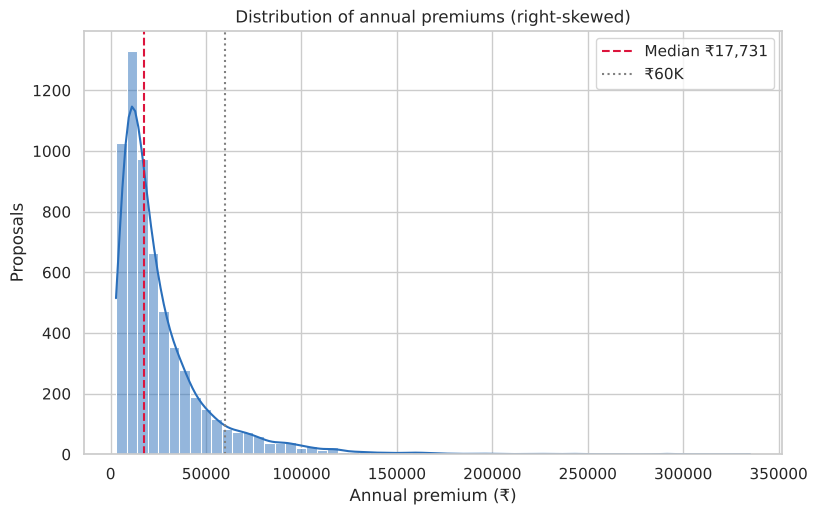

Median premium: ₹17,731 | share above ₹60K: 8.9%


In [7]:
show(plots.chart01_premium_distribution(eda), "01_premium_distribution.png")
print(f"Median premium: ₹{eda[TARGET].median():,.0f} | share above ₹60K: {(eda[TARGET] > 60000).mean():.1%}")

**Insight 1.** Premiums are right-skewed: the median is about ₹17.7K, but older families with high cover and declared conditions form a long tail above ₹60K (about 9% of proposals). A model on raw rupees will be dominated by that tail, which is why the log premium is worth trying.

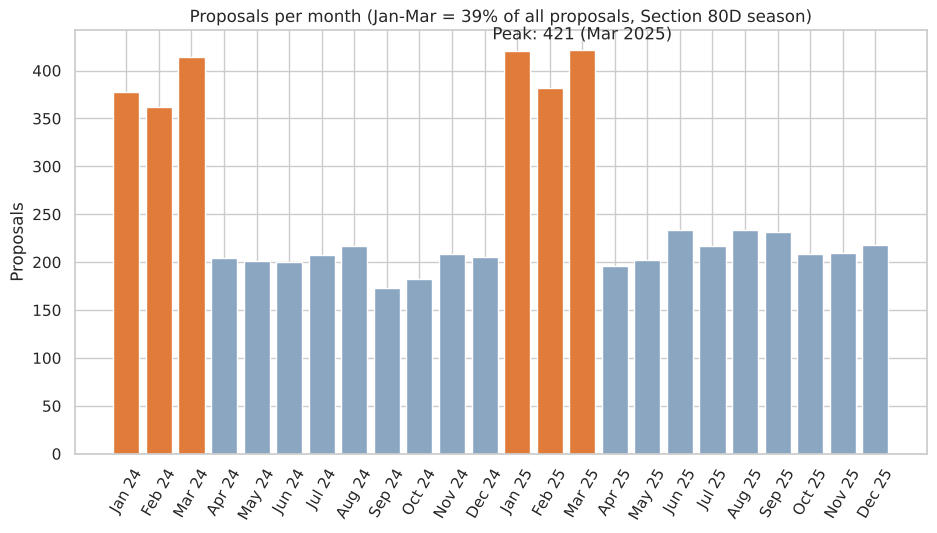

In [8]:
fig = plots.chart02_monthly_volume(eda)
show(fig, "02_proposals_per_month.png")

**Insight 2.** Volumes jump every January - March as customers buy for the Section 80D tax deduction: these three months bring about 39% of all proposals, peaking at 421 in March 2025. Underwriting capacity and the instant-quote tool matter most in this window.

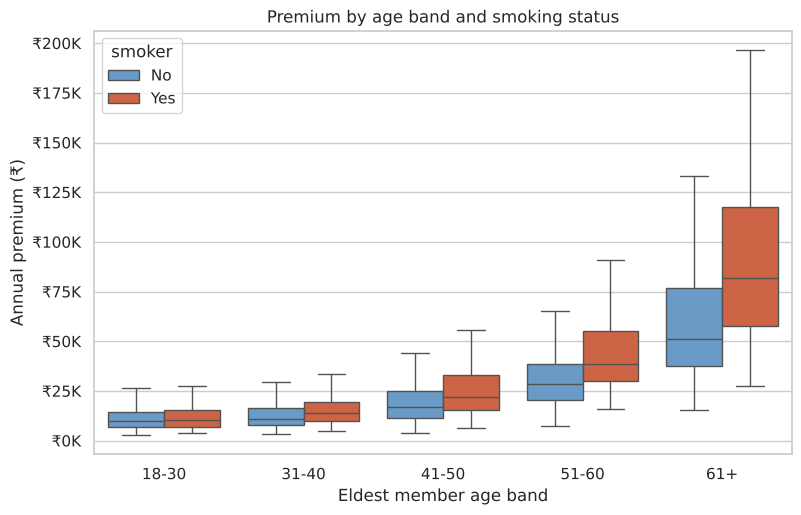

smoker,No,Yes
band,,
18-30,9674.0,10550.0
31-40,11119.0,13992.0
41-50,16696.0,21823.0
51-60,28325.0,38446.0
61+,50953.0,81736.0


In [9]:
show(plots.chart03_premium_age_smoker(eda), "03_premium_by_age_smoking.png")
eda.assign(band=pd.cut(eda.eldest_member_age, [17, 30, 40, 50, 60, 120],
                       labels=["18-30", "31-40", "41-50", "51-60", "61+"])) \
   .groupby(["band", "smoker"], observed=True)[TARGET].median().unstack().round(0)

**Insight 3.** The median premium for non-smokers rises from about ₹9.7K (age 18-30) to ₹51K (61+). The smoker gap widens with age: at 61+ smokers pay a median ₹81.7K, about 60% more, while at 18-30 the gap is under 10%.

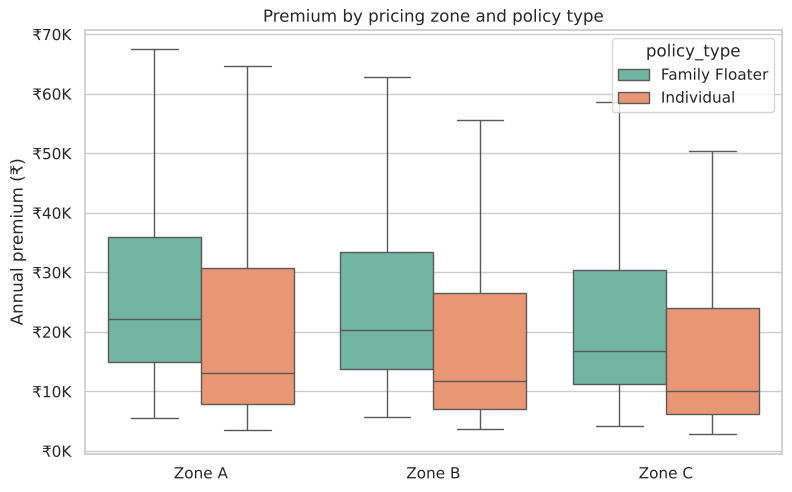

policy_type,Family Floater,Individual
zone,,
Zone A,22208.0,13150.0
Zone B,20398.0,11759.0
Zone C,16763.0,10058.0


In [10]:
show(plots.chart04_premium_zone_policy(eda), "04_premium_by_zone_policy.png")
eda.groupby(["zone", "policy_type"])[TARGET].median().unstack().round(0)

**Insight 4.** A family floater in metro Zone A has a median premium of ₹22.2K against ₹16.8K in Zone C, and individual policies cost roughly 60% of floaters in every zone.

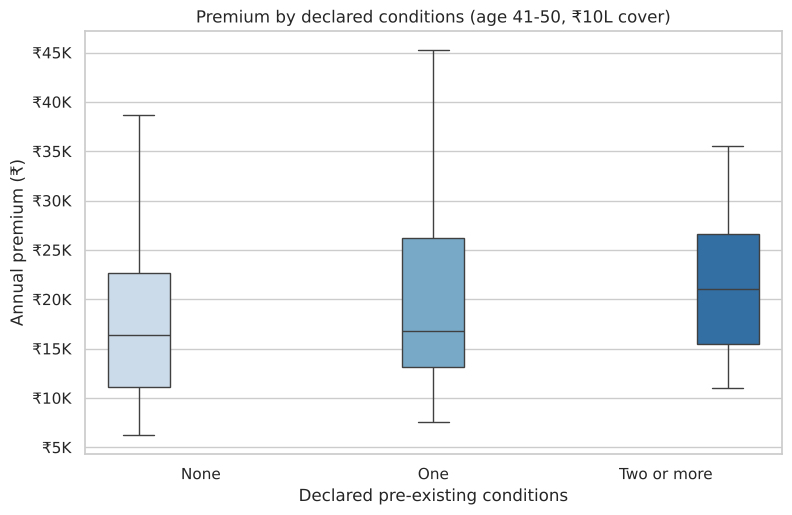

In [11]:
show(plots.chart05_premium_conditions(eda), "05_premium_by_conditions.png")

**Insight 5.** For proposers aged 41-50 with ₹10L cover, the median premium rises from about ₹16.3K (no condition) to ₹16.8K (one) and ₹21.1K (two or more, a small group). Family size and smoking explain the wide spread inside each box, so conditions alone are a modest driver compared with age.

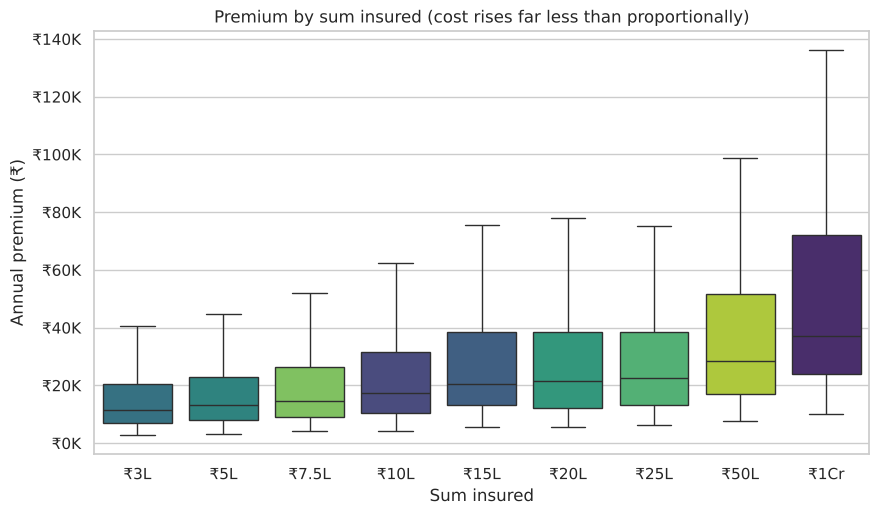

₹1 Cr cover costs 2.8x a ₹5L cover (20x the cover)


In [12]:
show(plots.chart06_premium_sum_insured(eda), "06_premium_by_sum_insured.png")
med = eda.groupby("sum_insured_inr")[TARGET].median()
print(f"₹1 Cr cover costs {med[10_000_000] / med[500_000]:.1f}x a ₹5L cover (20x the cover)")

**Insight 6.** Higher cover costs more, but far less than proportionally: a ₹1 Cr cover costs only about 2.8 times a ₹5L cover. Customers are being offered a strong price incentive to buy more cover.

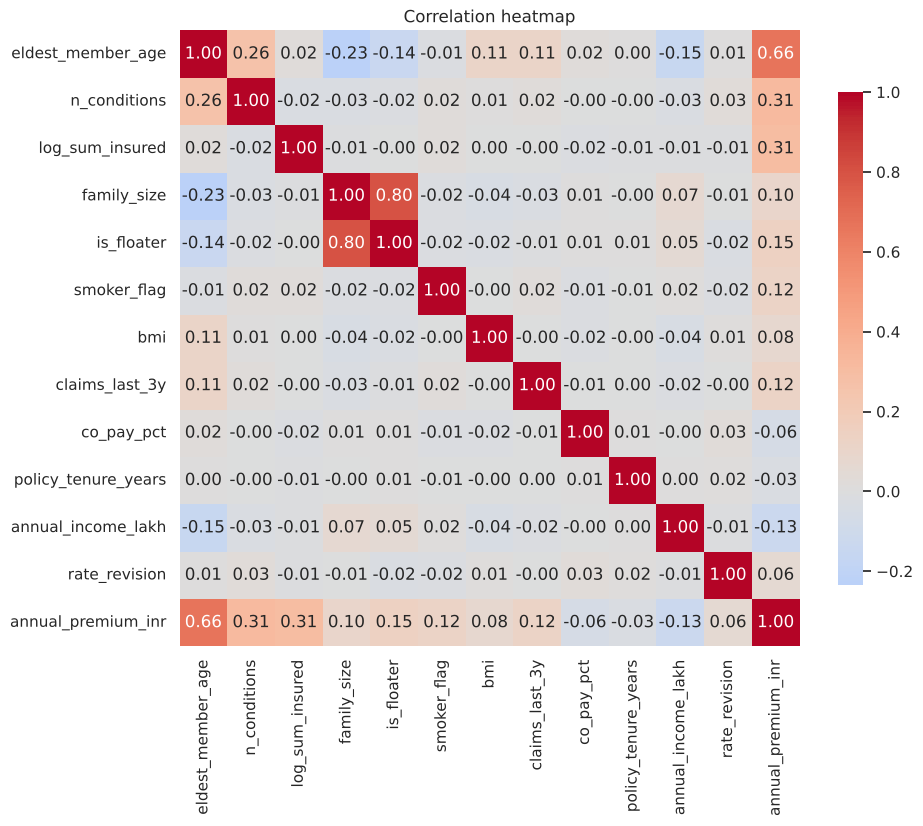

In [13]:
show(plots.chart07_correlation_heatmap(eda), "07_correlation_heatmap.png")

**Insight 7.** Age has by far the strongest correlation with the premium (about 0.66), followed by the number of declared conditions and sum insured (about 0.31 each). Co-pay and tenure are weak, negative factors, as expected for discounts.

## 4. Feature engineering & time-ordered split (Milestone 3)
Rating features built by `FeatureEngineer` (inside the pipeline): one flag per declared condition (5), condition count,
obesity flag (BMI ≥ 30), smoker flag, **smoker × age**, family size, floater flag, **log sum insured**, an age-over-40 hinge
(the age effect is flat-ish then steep), check-up flag and the **rate-revision flag** (proposals from 1 Apr 2025).

`adults_covered` / `children_covered` (they add up to family size) and the condition count (sum of the five flags) stay in the
data but are left out of the model matrix: they are exact linear combinations of other columns and would make the
linear-model loadings meaningless.

**Split by date, not at random:** train on Jan 2024 - Jun 2025, test on Jul - Dec 2025. This mimics real use (price future
proposals) and tests the model across the rate revision.

In [14]:
X_train, y_train, X_test, y_test = time_split(df)
print(f"Train: {len(X_train):,} rows  {X_train.proposal_date.min():%b %Y} - {X_train.proposal_date.max():%b %Y}")
print(f"Test : {len(X_test):,} rows  {X_test.proposal_date.min():%b %Y} - {X_test.proposal_date.max():%b %Y}")

Train: 4,807 rows  Jan 2024 - Jun 2025
Test : 1,318 rows  Jul 2025 - Dec 2025


## 5. Models, pipelines and 5-fold cross-validation
Five models, each in a `Pipeline`: `ClinicalImputer → FeatureEngineer → ColumnTransformer → model`.
Scaled inputs and one-hot encoding (first level dropped) for the linear models, unscaled for the trees. The imputer, scaler
and encoder are fitted inside each CV fold, so there is no leakage. The best model is chosen on **CV RMSE** (training months
only), never on the test set.

In [15]:
models = build_models()
models["Linear Regression (log target)"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('impute', ...), ('features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_na

In [16]:
table, fitted, preds = compare_models(models, X_train, y_train, X_test, y_test)
best_name = table["cv_RMSE"].idxmin()
print("Best model by 5-fold CV RMSE:", best_name)
table.round(3)

Best model by 5-fold CV RMSE: Linear Regression (log target)


,cv_RMSE,cv_RMSE_std,cv_R2,test_MAE,test_MSE,test_RMSE,test_R2,test_MAPE_%,test_within_10pct_%
model,,,,,,,,,
Linear Regression,11851.792,1433.649,0.791,7825.567,2.438819e+08,15616.720,0.738,40.946,21.927
Linear Regression (log target),1429.837,202.485,0.997,842.139,4.371045e+06,2090.704,0.995,2.700,98.255
Decision Tree,11329.797,1132.712,0.808,6165.882,1.955279e+08,13983.128,0.790,18.182,34.143
Random Forest,8282.032,1101.189,0.897,4310.635,1.355967e+08,11644.600,0.855,11.344,54.021
Gradient Boosting,4978.445,915.640,0.962,2543.161,5.742663e+07,7578.036,0.938,7.656,73.065


## 6. Test evaluation (Milestone 4)
MAE, MSE, RMSE, R² and MAPE on the unseen Jul - Dec 2025 proposals, plus the share of quotes within ±10% of the underwriter.

In [17]:
test_cols = ["test_MAE", "test_MSE", "test_RMSE", "test_R2", "test_MAPE_%", "test_within_10pct_%"]
table[test_cols].sort_values("test_RMSE").round(3)

,test_MAE,test_MSE,test_RMSE,test_R2,test_MAPE_%,test_within_10pct_%
model,,,,,,
Linear Regression (log target),842.139,4.371045e+06,2090.704,0.995,2.700,98.255
Gradient Boosting,2543.161,5.742663e+07,7578.036,0.938,7.656,73.065
Random Forest,4310.635,1.355967e+08,11644.600,0.855,11.344,54.021
Decision Tree,6165.882,1.955279e+08,13983.128,0.790,18.182,34.143
Linear Regression,7825.567,2.438819e+08,15616.720,0.738,40.946,21.927


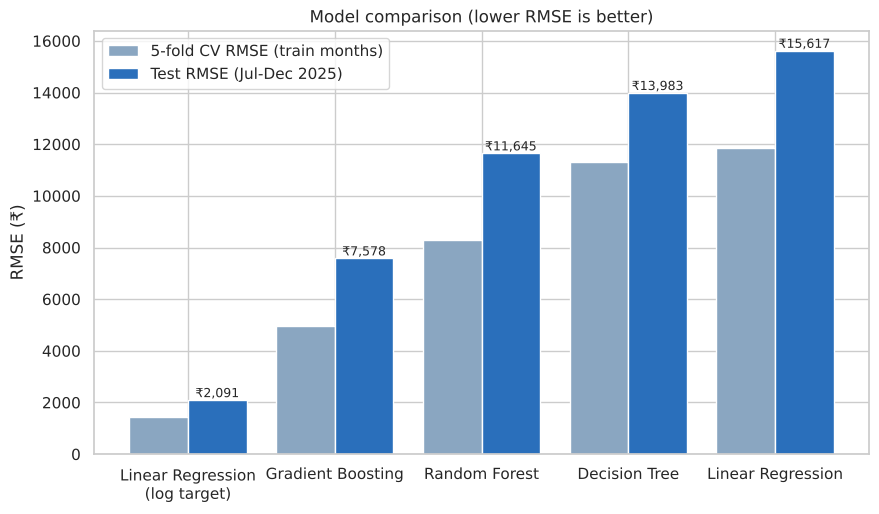

In [18]:
show(plots.chart08_model_comparison(table), "08_model_comparison.png")

**Insight 8.** Linear Regression on the log premium is the most accurate model, well ahead of Gradient Boosting. Plain Linear Regression and a single Decision Tree are the weakest. Premiums are built by multiplying rating factors, which is a straight line on the log scale; trees have to approximate this with steps and cannot extrapolate above the premiums they saw in training (relevant after the rate revision).

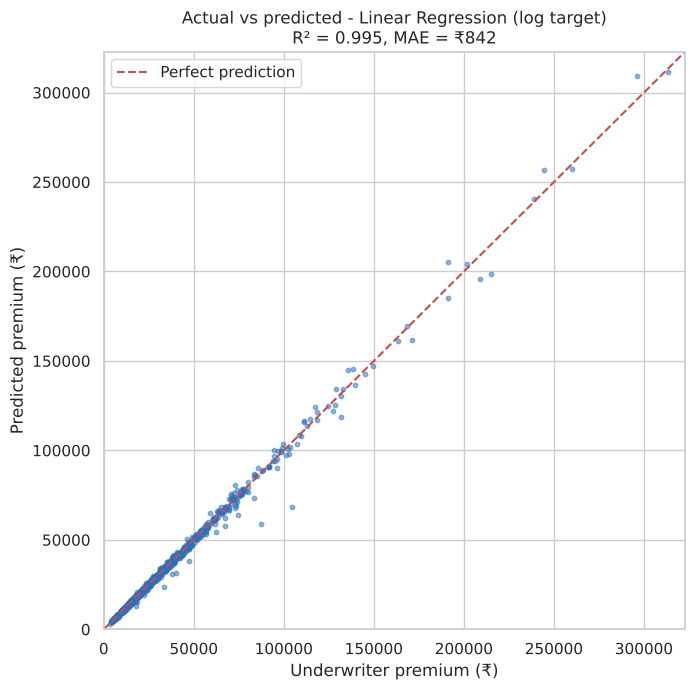

{'MAE': 842.139, 'MSE': 4371044.649, 'RMSE': 2090.704, 'R2': 0.995, 'MAPE_%': 2.7, 'within_10pct_%': 98.255}


In [19]:
best_pred = preds[best_name]
m = regression_metrics(y_test, best_pred)
show(plots.chart09_actual_vs_predicted(y_test, best_pred, best_name, m["R2"], m["MAE"]),
     "09_actual_vs_predicted.png")
print({k: round(v, 3) for k, v in m.items()})

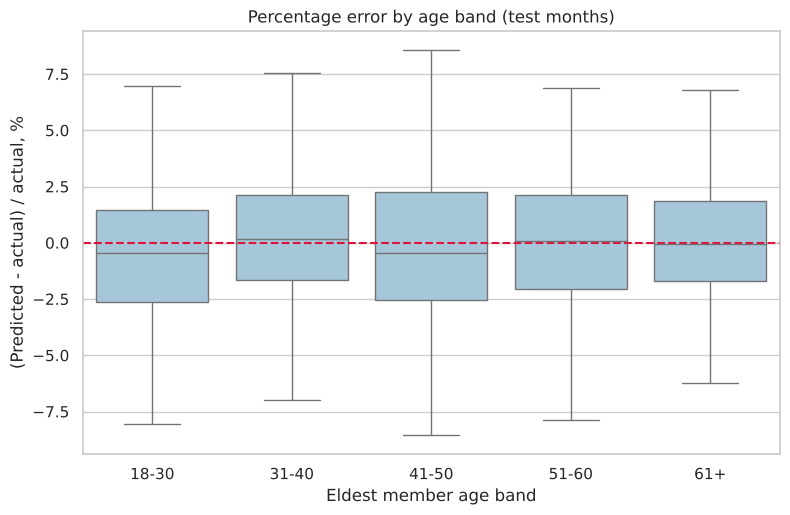

,mean_pct_error,median_pct_error,mean_abs_pct_error
age_band,,,
18-30,-0.54,-0.46,2.58
31-40,0.22,0.15,2.61
41-50,-0.24,-0.43,2.88
51-60,-0.11,0.07,2.51
61+,-0.63,-0.07,2.94


In [20]:
err_df, err_summary = error_by_age_band(X_test, y_test, best_pred)
show(plots.chart10_error_by_age(err_df), "10_error_by_age_band.png")
err_summary.round(2)

**Insight 9.** Percentage errors are centred on zero in every age band (mean error within ±1%, mean absolute error about 2.5-3%), so the model is not biased against young or senior proposers.

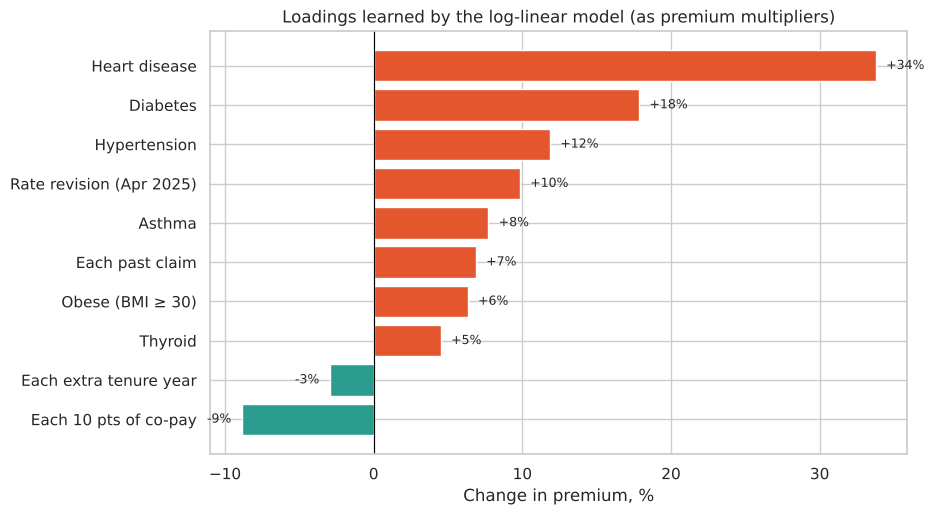

,premium change %
Each 10 pts of co-pay,-8.9
Each extra tenure year,-3.0
Thyroid,4.5
Obese (BMI ≥ 30),6.3
Each past claim,6.9
Asthma,7.7
Rate revision (Apr 2025),9.8
Hypertension,11.9
Diabetes,17.9
Heart disease,33.8


In [21]:
fig11, loadings = plots.chart11_loadings(fitted["Linear Regression (log target)"])
show(fig11, "11_log_linear_loadings.png")
(loadings * 100).round(1).rename("premium change %").to_frame()

**Insight 10.** Read as multipliers, the log-linear coefficients match underwriting practice: heart disease about +34%, diabetes +18%, hypertension +12%, each past claim +7%, and each 10 points of co-pay about -9%. The Appointed Actuary can compare these directly with the filed rate card.

## 7. Explaining the pricing with SHAP (Gradient Boosting)
`TreeExplainer` explains the tree model on the test months: global drivers, the age dependence split by smoking
status, and one individual quote.

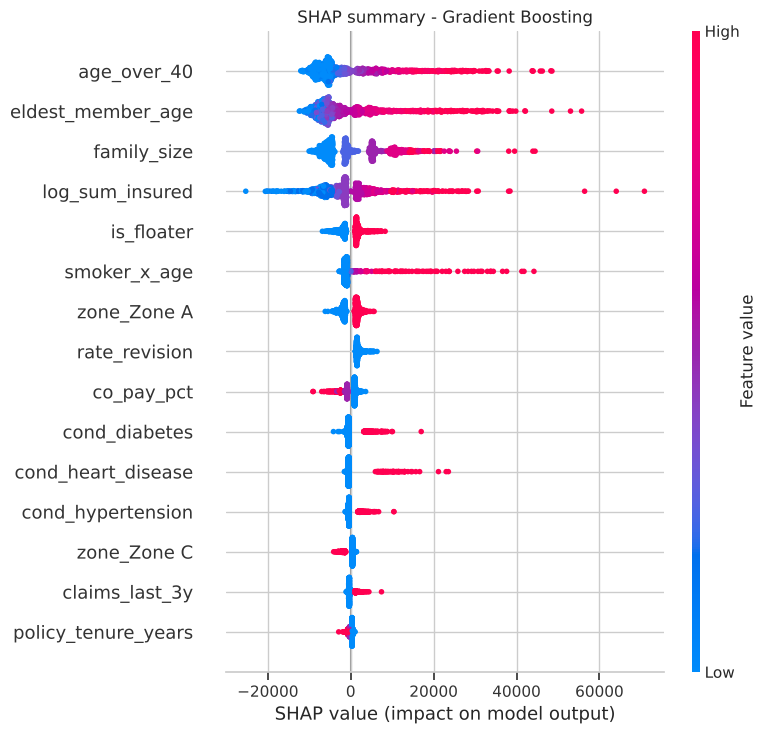

age_over_40          7745.0
eldest_member_age    7690.0
family_size          6335.0
log_sum_insured      5702.0
is_floater           2145.0
smoker_x_age         2107.0
zone_Zone A          1853.0
rate_revision        1839.0
co_pay_pct           1442.0
cond_diabetes        1232.0
dtype: float64

In [22]:
gb = fitted["Gradient Boosting"]
Xt = transformed_frame(gb, X_test)
explainer = shap.TreeExplainer(gb.named_steps["model"])
sv = explainer.shap_values(Xt)
base = float(np.ravel(explainer.expected_value)[0])
show(plots.chart12_shap_summary(sv, Xt), "12_shap_summary.png")
pd.Series(np.abs(sv).mean(axis=0), index=Xt.columns).sort_values(ascending=False).head(10).round(0)

**Insight 11.** SHAP ranks age (the two age features together) far above everything else, followed by family size and sum insured; floater status, smoker × age, the rate revision and Zone A come next. This agrees with the EDA and with underwriting practice.

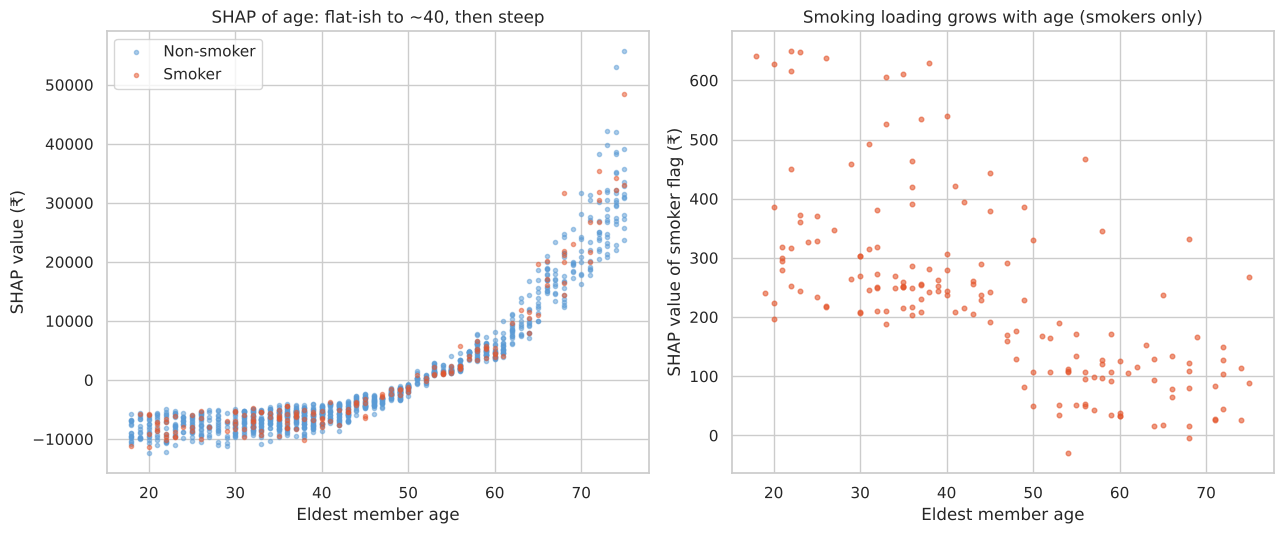

In [23]:
show(plots.chart13_shap_age_smoker(sv, Xt), "13_shap_age_smoker_dependence.png")

**Insight 12.** The age effect is flat-ish until about 40 and then climbs steeply. For smokers, the smoking loading grows steadily with age.

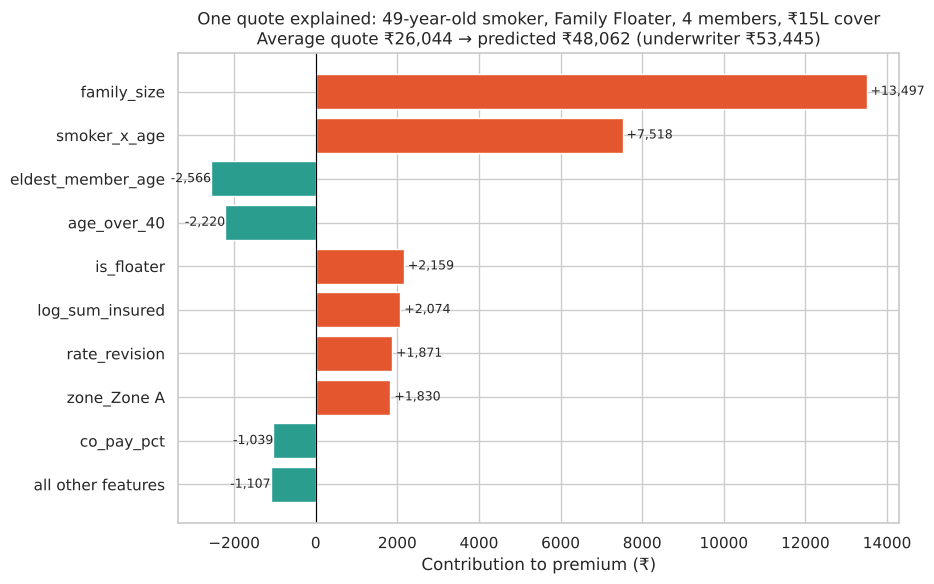

In [24]:
idx = plots.pick_example_quote(X_test, y_test)
pos = X_test.index.get_loc(idx)
row = X_test.loc[idx]
size = int(row.adults_covered + row.children_covered)
desc = (f"{int(row.eldest_member_age)}-year-old smoker, {row.policy_type}, {size} members, "
        f"₹{row.sum_insured_inr / 100000:g}L cover")
pred_gb = float(preds["Gradient Boosting"][pos])
show(plots.chart14_one_quote(pd.Series(sv[pos], index=Xt.columns), base, pred_gb,
                             float(y_test.loc[idx]), desc), "14_one_quote_explained.png")

**Insight 13.** For a single quote the bars add up exactly from the average quote to the prediction, so an agent can tell the customer: 'the four family members and your smoking at this age add the most; the age pattern and cover level are priced in too'. Underwriters can use the same view to review a quote that looks odd.

## 8. Save outputs and conclusions (Milestone 5)

In [25]:
table.round(4).to_csv(REPORT_DIR / "metrics.csv")
joblib.dump(fitted[best_name], MODEL_DIR / "best_model.joblib")
joblib.dump(fitted["Gradient Boosting"], MODEL_DIR / "gradient_boosting.joblib")
summary_path = REPORT_DIR / "summary.json"
print(summary_path.read_text() if summary_path.exists() else "run run_pipeline.py to create summary.json")

{
  "dataset": {
    "raw_rows": 6242,
    "clean_rows": 6125,
    "train_rows": 4807,
    "test_rows": 1318,
    "split_date": "2025-07-01",
    "seed": 42
  },
  "best_model_by_cv_rmse": "Linear Regression (log target)",
  "best_model_test_metrics": {
    "MAE": 842.1386,
    "MSE": 4371044.6495,
    "RMSE": 2090.7043,
    "R2": 0.9953,
    "MAPE_%": 2.7,
    "within_10pct_%": 98.2549
  },
  "gradient_boosting_test_metrics": {
    "MAE": 2543.1607,
    "MSE": 57426631.3246,
    "RMSE": 7578.0361,
    "R2": 0.9384,
    "MAPE_%": 7.6557,
    "within_10pct_%": 73.0653
  },
  "success_criteria": {
    "test_R2_>=_0.95": true,
    "test_MAPE_<_8%": true,
    "share_within_10pct_>=_75%": true
  },
  "top_shap_features": [
    "age_over_40",
    "eldest_member_age",
    "family_size",
    "log_sum_insured",
    "is_floater",
    "smoker_x_age",
    "zone_Zone A",
    "rate_revision"
  ],
  "example_quote": {
    "description": "49-year-old smoker, Family Floater, 4 members, ₹15L cover",
   

### Five insights
1. **Age drives the premium** (correlation about 0.66, top SHAP feature): flat-ish to about 40, then a steep climb.
2. **Smoking is an age-dependent loading**: small at 18-30, about +60% on the median at 61+.
3. **Cover is priced sub-proportionally**: 20x the cover costs about 2.8x the premium.
4. **Pricing is multiplicative**, so a log-linear model beats the tree models on accuracy *and* is the easiest to audit against the rate card.
5. **Demand is seasonal**: Jan - Mar brings about 39% of proposals (Section 80D), so quote speed matters most then.

### Three recommendations
1. **Instant indicative quotes.** Put the log-linear model behind the agent / bank-partner / web quote app; about 98% of test quotes were within ±10% of the underwriter.
2. **Underwriting review shortlist.** Auto-quote the rest and send to manual review only quotes where the log-linear and Gradient Boosting predictions disagree, or where the customer is outside the training range (very high cover, age 61+ with several conditions).
3. **Consistency and governance.** Give underwriters the factor-by-factor breakdown to cut the up-to-15% gap between underwriters, retrain after every rate revision or at least every six months, and monitor error by age band.